In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU available: []


In [ ]:
!pip install -q librosa soundfile

In [ ]:
import librosa
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt

print("Librosa version:", librosa.__version__)
print("Libraries loaded successfully!")

Librosa version: 0.11.0
Libraries loaded successfully!


In [ ]:
import os
import urllib.request
import tarfile

url = "http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz"

dataset_path = "/content/speech_commands"

os.makedirs(dataset_path, exist_ok=True)

print("Downloading Speech Commands dataset...")
urllib.request.urlretrieve(
    url,
    "/content/speech_commands.tar.gz"
)

print("Download completed!")

print("Extracting dataset...")
with tarfile.open("/content/speech_commands.tar.gz", "r:gz") as tar:
    tar.extractall(dataset_path)

print("Dataset extracted successfully!")

Download completed!
Extracting dataset...


/tmp/ipykernel_812/2625929716.py:21: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(dataset_path)


Dataset extracted successfully!


In [ ]:
import os
import shutil
import random

SOURCE_DIR = "/content/speech_commands"
DATA_DIR = "/content/keyword_dataset"

# Create folders
os.makedirs(DATA_DIR, exist_ok=True)

for label in ["on", "off", "unknown"]:
    os.makedirs(os.path.join(DATA_DIR, label), exist_ok=True)

# Copy ON samples
on_files = [
    f for f in os.listdir(os.path.join(SOURCE_DIR, "on"))
    if f.endswith(".wav")
]

for f in on_files:
    shutil.copy(
        os.path.join(SOURCE_DIR, "on", f),
        os.path.join(DATA_DIR, "on", f)
    )

# Copy OFF samples
off_files = [
    f for f in os.listdir(os.path.join(SOURCE_DIR, "off"))
    if f.endswith(".wav")
]

for f in off_files:
    shutil.copy(
        os.path.join(SOURCE_DIR, "off", f),
        os.path.join(DATA_DIR, "off", f)
    )

# Select UNKNOWN samples from other words
excluded_words = {
    "on", "off", "_background_noise_"
}

other_words = [
    d for d in os.listdir(SOURCE_DIR)
    if os.path.isdir(os.path.join(SOURCE_DIR, d))
    and d not in excluded_words
]

unknown_files = []

for word in other_words:
    word_path = os.path.join(SOURCE_DIR, word)

    for f in os.listdir(word_path):
        if f.endswith(".wav"):
            unknown_files.append(
                os.path.join(word_path, f)
            )

# Randomly select same approximate number as ON samples
random.seed(42)
random.shuffle(unknown_files)

unknown_files = unknown_files[:len(on_files)]

for i, source_file in enumerate(unknown_files):
    destination = os.path.join(
        DATA_DIR,
        "unknown",
        f"unknown_{i}.wav"
    )
    shutil.copy(source_file, destination)

# Show dataset counts
print("Dataset prepared successfully!\n")

for label in ["on", "off", "unknown"]:
    count = len([
        f for f in os.listdir(os.path.join(DATA_DIR, label))
        if f.endswith(".wav")
    ])
    print(f"{label.upper():8} : {count} samples")

Dataset prepared successfully!

ON       : 3845 samples
OFF      : 3745 samples
UNKNOWN  : 3845 samples


ON SAMPLE
File: cce17a61_nohash_1.wav
Sampling rate: 16000 Hz
Duration: 1.0 seconds

OFF SAMPLE
File: 5f8097e1_nohash_2.wav
Sampling rate: 16000 Hz
Duration: 1.0 seconds

UNKNOWN SAMPLE
File: unknown_421.wav
Sampling rate: 16000 Hz
Duration: 1.0 seconds



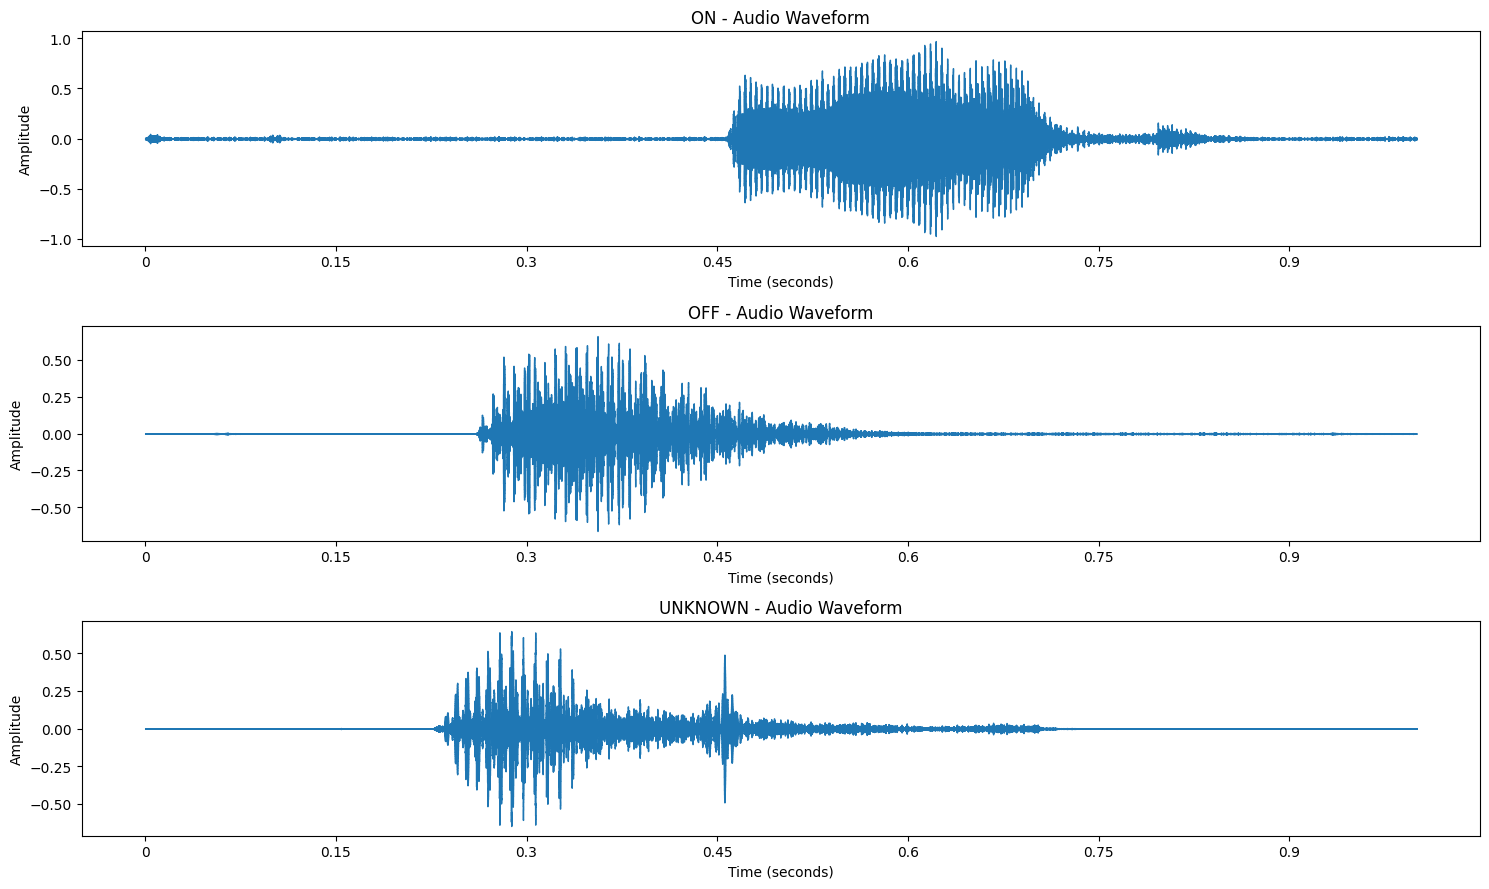

In [ ]:
import os
import librosa
import librosa.display
import matplotlib.pyplot as plt

labels = ["on", "off", "unknown"]

plt.figure(figsize=(15, 9))

for i, label in enumerate(labels):

    folder = os.path.join(DATA_DIR, label)

    files = [
        f for f in os.listdir(folder)
        if f.endswith(".wav")
    ]

    file_path = os.path.join(folder, files[0])

    # Load audio
    audio, sr = librosa.load(file_path, sr=None)

    # Display information
    print(f"{label.upper()} SAMPLE")
    print("File:", files[0])
    print("Sampling rate:", sr, "Hz")
    print("Duration:", round(len(audio) / sr, 3), "seconds")
    print()

    # Plot waveform
    plt.subplot(3, 1, i + 1)

    librosa.display.waveshow(audio, sr=sr)

    plt.title(f"{label.upper()} - Audio Waveform")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [ ]:
!pip install -q tensorflow tensorflow-datasets librosa soundfile matplotlib numpy pandas scikit-learn